In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.path import Path

### Material and Light class

In [2]:
class PhongMaterial:
    def __init__(self, k_a, k_d, k_s, alpha):
        self.k_a = np.array(k_a, dtype=float)           # Môi trường Ambient Light
        self.k_d = np.array(k_d, dtype=float)           # Khuếch tán Diffuse Light
        self.k_s = np.array(k_s, dtype=float)           # Phản xạ Gương Specular Light
        self.alpha = float(alpha)                       # Độ bóng

class LightSource:
    def __init__(self, position, intensity_diffuse, intensity_specular, light_type="point"):
        self.position = np.array(position, dtype=float)                 # Vị trí nguồn sáng (x, y, z)
        self.intensity_diffuse = intensity_diffuse  # Cường độ màu sắc của nguồn sáng (RGB)
        self.intensity_specular = intensity_specular
        self.light_type = light_type                                    # Loại nguồn sáng: "point" hoặc "directional" 

In [3]:
def normalize(v):
    norm = np.linalg.norm(v)
    if norm == 0:
        return v
    return v / norm

def dot_product(v1, v2):
    return np.dot(v1, v2)

def reflect(incident_vector, normal_vector):
    """Tính toán vector phản xạ

    Args:
        incident_vector (np.ndarray): Vector tới điểm bị phản xạ
        normal_vector (np.ndarray): Vector pháp tuyến tại điểm bị phản xạ

    Returns:
        np.ndarray: Vector phản xạ
    """
    return normalize(2 * dot_product(normal_vector, incident_vector) * normal_vector - incident_vector)

### Set up ngôi sao

In [4]:
def create_star_vertices(center_x, center_y, outer_radius, inner_radius, num_points=5):
    angles_outer = np.linspace(0, 2 * np.pi, num_points + 1)[:-1] + np.pi / 2 # Bắt đầu từ đỉnh trên
    angles_inner = angles_outer + np.pi / num_points

    vertices = []
    for i in range(num_points):
        # Đỉnh ngoài
        x_outer = center_x + outer_radius * np.cos(angles_outer[i])
        y_outer = center_y + outer_radius * np.sin(angles_outer[i])
        vertices.append([int(x_outer), int(y_outer)])

        # Đỉnh trong
        x_inner = center_x + inner_radius * np.cos(angles_inner[i])
        y_inner = center_y + inner_radius * np.sin(angles_inner[i])
        vertices.append([int(x_inner), int(y_inner)])
    return np.array(vertices)

In [5]:
# 1. Hình ngôi sao
w, h = 400, 400
img = np.zeros((h, w), dtype=np.uint8) 
star_center = np.array([w//2, h//2]) # Tâm ngôi sao (x, y)
star_outer_radius = 150
star_inner_radius = 70
star_vertices_2d = create_star_vertices(star_center[0], star_center[1], star_outer_radius, star_inner_radius)

star_vertices_2d

array([[200, 350],
       [158, 256],
       [ 57, 246],
       [133, 178],
       [111,  78],
       [200, 130],
       [288,  78],
       [266, 178],
       [342, 246],
       [241, 256]])

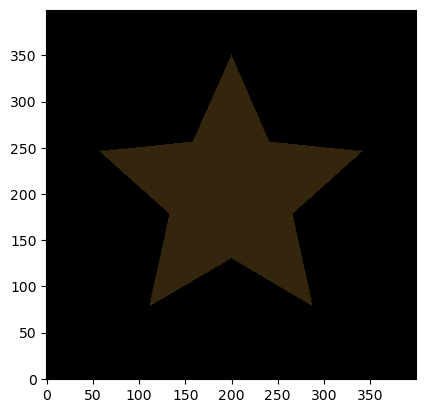

In [6]:
star_img = np.zeros((h, w, 3), dtype=np.float32)

# Tạo mặt nạ ngôi sao (mask) để xác định điểm nào nằm trong ngôi sao
star_path = Path(star_vertices_2d)
yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing='ij')
points = np.stack((xx.ravel(), yy.ravel()), axis=-1)
mask = star_path.contains_points(points).reshape(h, w)

star_img[mask] = [0.2, 0.15, 0.05]  # Màu vàng cho ngôi sao

plt.imshow(star_img, origin='lower')

### Phong model

In [7]:
def phong_reflection_model(
    point_on_surface_3d,    # Điểm này bây giờ sẽ có thành phần z
    normal_vector_3d,       # Pháp tuyến 3D
    view_vector_3d,         # Vector nhìn 3D
    material,               # Vật liệu chứa các thông số Phong
    light_sources,          # Danh sách các nguồn sáng
    ambient_light_intensity # Cường độ ánh sáng môi trường (RGB)
):
    N = normalize(normal_vector_3d)
    V = normalize(view_vector_3d)
    ambient_color = material.k_a * ambient_light_intensity
    diffuse_color = np.array([0.0, 0.0, 0.0])   # Màu khuếch tán
    specular_color = np.array([0.0, 0.0, 0.0])  # Màu phản xạ

    for light in light_sources:
        if light.light_type == "point":
            L = normalize(light.position - point_on_surface_3d)
        elif light.light_type == "directional":
            L = normalize(light.position) # light.position là hướng chiếu
        else:
            continue

        n_dot_l = dot_product(N, L)
        current_diffuse = material.k_d * light.intensity_diffuse * max(0.0, n_dot_l)
        diffuse_color += current_diffuse

        if n_dot_l > 0:
            R = reflect(L, N) # Tính vector phản xạ
            r_dot_v = dot_product(R, V)
            specular_term = pow(max(0.0, r_dot_v), material.alpha)
            current_specular = material.k_s * light.intensity_specular * specular_term
            specular_color += current_specular

    final_color = ambient_color + diffuse_color + specular_color
    return np.clip(final_color, 0.0, 1.0) # đảm bảo màu trong khoảng 0 -> 1

In [8]:
R = np.array([0.0, 0.0, 1.0])  # Vector pháp tuyến (z hướng lên)
V = np.array([0.0, 2, 2])  # Vector nhìn (z hướng lên)
V = normalize(V)
material = PhongMaterial(k_a=[0.2, 0.15, 0.05], k_d=[0.8, 0.7, 0.6], k_s=[0.15, 0.15, 0.15], alpha=10)
r_dot_v = dot_product(R, V)
specular_term = pow(max(0.0, r_dot_v), material.alpha)
current_specular = material.k_s * 30 * specular_term
current_specular

array([0.140625, 0.140625, 0.140625])

### Thiết lập thông số khối 3d

In [9]:
# Tâm ngôi sao có z, tức là nhô lên
point_on_star_center_3d = np.array([star_center[0], star_center[1], 120])

# Các đỉnh sẽ có z=0
star_vertices_3d = np.hstack((star_vertices_2d, np.zeros((star_vertices_2d.shape[0], 1))))  # Thêm thành phần z=0
star_vertices_3d

array([[200., 350.,   0.],
       [158., 256.,   0.],
       [ 57., 246.,   0.],
       [133., 178.,   0.],
       [111.,  78.,   0.],
       [200., 130.,   0.],
       [288.,  78.,   0.],
       [266., 178.,   0.],
       [342., 246.,   0.],
       [241., 256.,   0.]])

### Nội suy khối 3d

In [10]:
def find_nearest_inner_and_outer_vertices(point):
  """
  Tìm 2 đỉnh gồm 1 đỉnh trong, 1 đỉnh ngoài gần nhất với điểm (x, y) bất kỳ.
  - point: tuple hoặc array (x, y)
  - star_vertices_2d: mảng các đỉnh ngôi sao (ngoài và trong, xen kẽ)
  Trả về: chỉ số và toạ độ 2 đỉnh (1 trong, 1 ngoài) gần nhất
  """
  # Đỉnh ngoài: chỉ số chẵn, đỉnh trong: chỉ số lẻ
  outer_indices = np.arange(0, len(star_vertices_2d), 2)
  inner_indices = np.arange(1, len(star_vertices_2d), 2)
  outer_vertices = star_vertices_2d[outer_indices]
  inner_vertices = star_vertices_2d[inner_indices]

  dist_outer = np.linalg.norm(outer_vertices - point, axis=1)
  dist_inner = np.linalg.norm(inner_vertices - point, axis=1)

  nearest_outer_idx = outer_indices[np.argmin(dist_outer)]
  nearest_inner_idx = inner_indices[np.argmin(dist_inner)]

  return nearest_inner_idx, nearest_outer_idx

# Ví dụ sử dụng:
find_nearest_inner_and_outer_vertices((100, 100))

(np.int64(3), np.int64(4))

In [11]:
def interpolate_z_on_star(point):
  """
  point chỉ có (x, y) -> cần tìm z.
  Trả về (A, B, C, D) của phương trình mặt phẳng: Ax + By + Cz + D = 0
  đi qua 3 điểm p1, p2, p3 (mỗi điểm là array-like 3 phần tử)
  """
  p1 = point_on_star_center_3d
  id1, id2 = find_nearest_inner_and_outer_vertices(point)
  p2, p3 = star_vertices_3d[id1], star_vertices_3d[id2]
  # Hai vector trên mặt phẳng
  v1 = p2 - p1
  v2 = p3 - p1
  # Vector pháp tuyến
  normal = np.cross(v1, v2)
  A, B, C = normal
  # Tìm D bằng cách thế p1 vào phương trình
  D = - (A * p1[0] + B * p1[1] + C * p1[2])
  z = (-D - A * point[0] - B * point[1]) / C
  return np.array([point[0], point[1], z])

interpolate_z_on_star((120, 170))

array([120.       , 170.       , -21.6988417])

In [12]:
def compute_normal_from_points(p1, p2, p3):
    """
    Tính vector pháp tuyến của mặt phẳng qua 3 điểm.
    """
    v1 = p2 - p1
    v2 = p3 - p1
    normal = np.cross(v1, v2)
    norm = np.linalg.norm(normal)
    if norm == 0:
        return np.array([0, 0, 1])  # fallback: hướng thẳng đứng
    if normal[2] < 0:
        normal = -normal
    return normal

point = (225, 225)  # Điểm bất kỳ trên mặt phẳng ngôi sao
point_on_surface_3d = interpolate_z_on_star(point)
id1, id2 = find_nearest_inner_and_outer_vertices(point)
p1 = point_on_star_center_3d 
p2 = star_vertices_3d[id2]
p3 = star_vertices_3d[id1]
normal_vector_3d = compute_normal_from_points(p1, p2, p3)
normal_vector_3d


array([ 1200., 12120.,  6066.])

### Thông số

In [21]:
# Ví dụ cho vật liệu KIM LOẠI MÀU VÀNG RẤT BÓNG
gold_metal = PhongMaterial(
    k_a=[0.2, 0.15, 0.05], # Ambient thấp
    k_d=[0.3, 0.2, 0.05],  # Kim loại thường có diffuse thấp hơn và mang màu
    k_s=[0.15, 0.15, 0.15], # K_s RẤT CAO, MÀU VÀNG
    alpha= 20      # Alpha 
)

# Nguồn sáng mạnh
white_light = LightSource(
    position = np.array([1, 1, 2]), 
    intensity_diffuse = 5.0, # Cường độ tối đa cho màu trắng
    intensity_specular = 20.0,  # Cường độ phản xạ gương
    light_type="directional"  # Sử dụng ánh sáng hướng
)

white_light1 = LightSource(
    position = np.array([120, 170, 30]), 
    intensity_diffuse = 6.0, # Cường độ tối đa cho màu trắng
    intensity_specular = 5.0,  # Cường độ phản xạ gương
    light_type="point"  # Sử dụng ánh sáng hướng"
)

white_light2 = LightSource(
    position = np.array([200, 150, 60]), 
    intensity_diffuse = 5.0, # Cường độ tối đa cho màu trắng
    intensity_specular = 5.0,  # Cường độ phản xạ gương
    light_type="point"  # Sử dụng ánh sáng hướng"
)

light_sources_list = [white_light, white_light1, white_light2]

# Ánh sáng môi trường có thể giữ ở mức vừa phải hoặc thấp
ambient_light = np.array([0.1, 0.1, 0.1])

# 4. Camera/Người xem
camera_position_3d = np.array([200, 200, 200])

### Tính toán màu

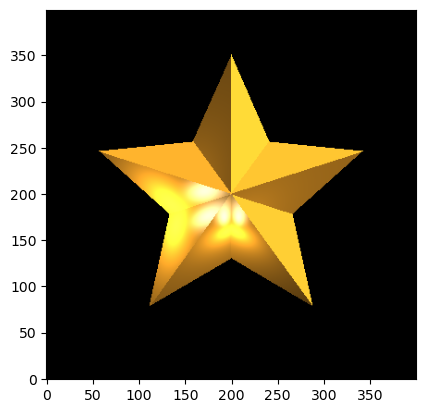

In [22]:
star_img_3d = star_img.copy() 

for i in range(h):
  for j in range(w):   
    if mask[i, j]:  # Chỉ xử lý các điểm nằm trong ngôi sao
      point = np.array([j, i]) # đảm bảo dạng (x, y)
      point_on_surface_3d = interpolate_z_on_star(point)
      id1, id2 = find_nearest_inner_and_outer_vertices(point)
      p1 = point_on_star_center_3d 
      p2 = star_vertices_3d[id1]
      p3 = star_vertices_3d[id2]
      normal_vector_3d = compute_normal_from_points(p1, p2, p3)
      view_vector_pixel = camera_position_3d - point_on_surface_3d
      color = phong_reflection_model(
          point_on_surface_3d,
          normal_vector_3d,
          view_vector_pixel,
          gold_metal,
          light_sources_list,
          ambient_light
      )
      star_img_3d[i, j] = color
      
plt.imshow(star_img_3d, origin='lower')

In [15]:
gold_metal = PhongMaterial(
    k_a=[0.2, 0.15, 0.05], # Ambient thấp
    k_d=[0.0, 0.0, 0.0],  # Kim loại thường có diffuse thấp hơn và mang màu
    k_s=[0.0, 0.0, 0.0], # K_s RẤT CAO, MÀU VÀNG
    alpha= 10      # Alpha 
)
ambient_light = 10*np.array([0.1, 0.1, 0.1])
star_img_3d_ambient = star_img.copy() 

for i in range(h):
  for j in range(w):   
    if mask[i, j]:  # Chỉ xử lý các điểm nằm trong ngôi sao
      point = np.array([j, i])
      point_on_surface_3d = interpolate_z_on_star(point)
      id1, id2 = find_nearest_inner_and_outer_vertices(point)
      p1 = point_on_star_center_3d 
      p2 = star_vertices_3d[id1]
      p3 = star_vertices_3d[id2]
      normal_vector_3d = compute_normal_from_points(p1, p2, p3)
      view_vector_pixel = camera_position_3d - point_on_surface_3d
      color = phong_reflection_model(
          point_on_surface_3d,
          normal_vector_3d,
          view_vector_pixel,
          gold_metal,
          light_sources_list,
          ambient_light
      )
      star_img_3d_ambient[i, j] = color
      
plt.imshow(star_img_3d_ambient, origin='lower')

KeyboardInterrupt: 

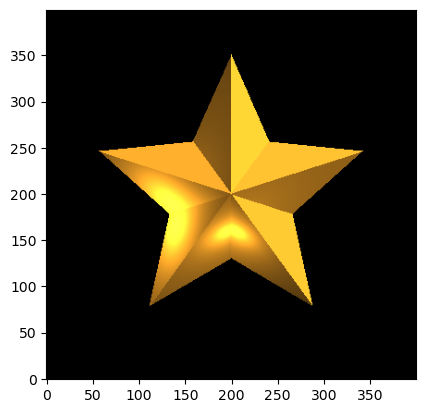

In [ ]:
gold_metal = PhongMaterial(
    k_a=[0.0, 0.0, 0.0], # Ambient thấp
    k_d=[0.3, 0.2, 0.05],  # Kim loại thường có diffuse thấp hơn và mang màu
    k_s=[0.0, 0.0, 0.0], # K_s RẤT CAO, MÀU VÀNG
    alpha= 10      # Alpha 
)
star_img_3d_diffuse = star_img.copy() 

for i in range(h):
  for j in range(w):   
    if mask[i, j]:  # Chỉ xử lý các điểm nằm trong ngôi sao
      point = np.array([j, i])
      point_on_surface_3d = interpolate_z_on_star(point)
      id1, id2 = find_nearest_inner_and_outer_vertices(point)
      p1 = point_on_star_center_3d 
      p2 = star_vertices_3d[id1]
      p3 = star_vertices_3d[id2]
      normal_vector_3d = compute_normal_from_points(p1, p2, p3)
      view_vector_pixel = camera_position_3d - point_on_surface_3d
      color = phong_reflection_model(
          point_on_surface_3d,
          normal_vector_3d,
          view_vector_pixel,
          gold_metal,
          light_sources_list,
          ambient_light
      )
      star_img_3d_diffuse[i, j] = color
      
plt.imshow(star_img_3d_diffuse, origin='lower')

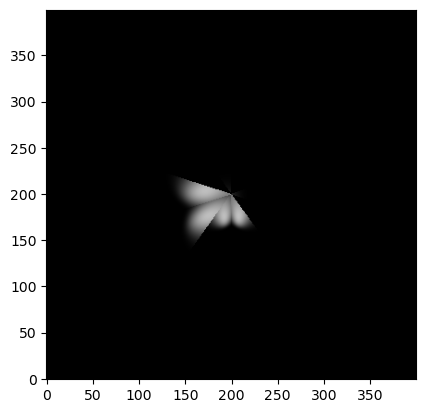

In [ ]:
gold_metal = PhongMaterial(
    k_a=[0.0, 0.0, 0.0], # Ambient thấp
    k_d=[0.0, 0.0, 0.0],  # Kim loại thường có diffuse thấp hơn và mang màu
    k_s=[0.15, 0.15, 0.15], # K_s RẤT CAO, MÀU VÀNG
    alpha= 10     # Alpha 
)
star_img_specular = star_img.copy() 

for i in range(h):
  for j in range(w):   
    if mask[i, j]:  # Chỉ xử lý các điểm nằm trong ngôi sao
      point = np.array([j, i])
      point_on_surface_3d = interpolate_z_on_star(point)
      id1, id2 = find_nearest_inner_and_outer_vertices(point)
      p1 = point_on_star_center_3d 
      p2 = star_vertices_3d[id1]
      p3 = star_vertices_3d[id2]
      normal_vector_3d = compute_normal_from_points(p1, p2, p3)
      view_vector_pixel = camera_position_3d - point_on_surface_3d
      color = phong_reflection_model(
          point_on_surface_3d,
          normal_vector_3d,
          view_vector_pixel,
          gold_metal,
          light_sources_list,
          ambient_light
      )
      star_img_specular[i, j] = color
      
plt.imshow(star_img_specular, origin='lower')

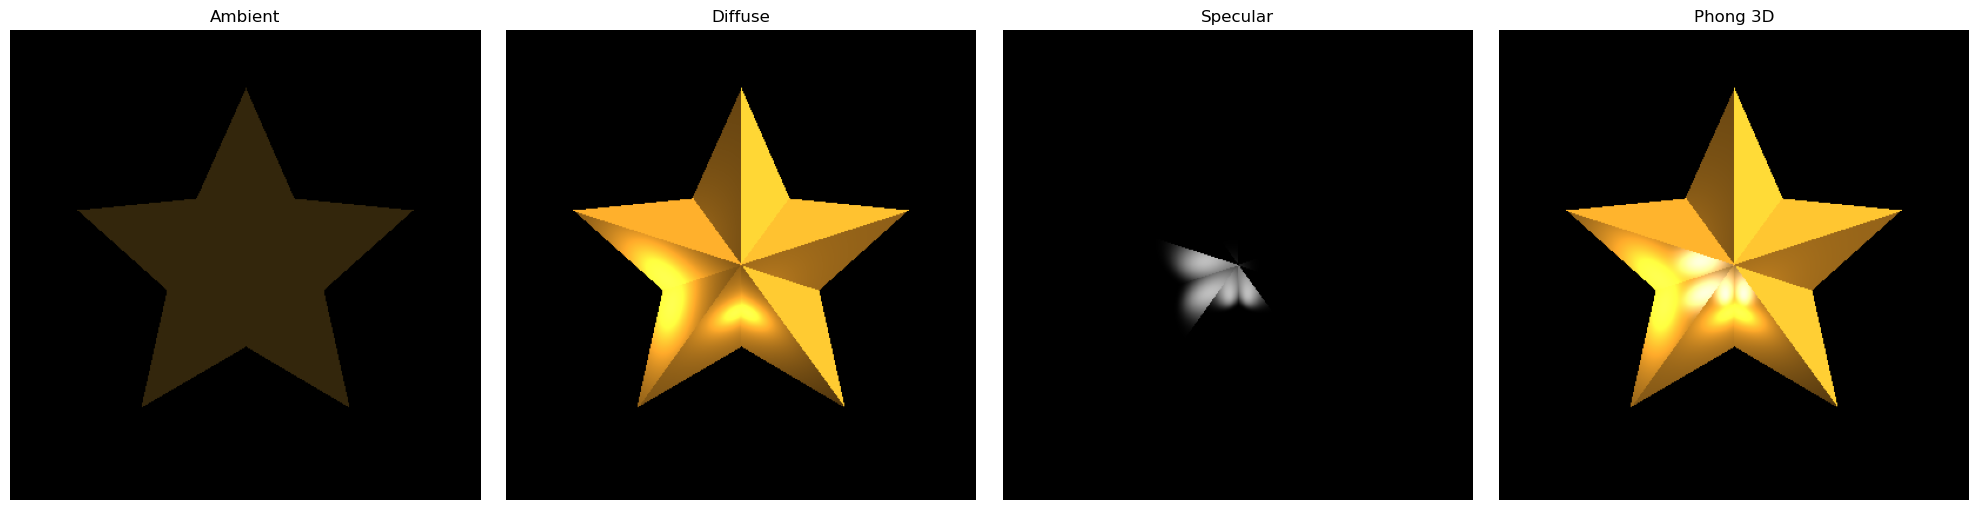

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(star_img_3d_ambient, origin='lower')
axes[0].set_title('Ambient')
axes[0].axis('off')

axes[1].imshow(star_img_3d_diffuse, origin='lower')
axes[1].set_title('Diffuse')
axes[1].axis('off')

axes[2].imshow(star_img_specular, origin='lower')
axes[2].set_title('Specular')
axes[2].axis('off')

axes[3].imshow(star_img_3d, origin='lower')
axes[3].set_title('Phong 3D')
axes[3].axis('off')

plt.tight_layout()
plt.show()